In [12]:
df = pd.read_csv('../data/processed/cleaned_retail.csv')
# Parse InvoiceDate correctly
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
# Calculate revenue
df['Revenue'] = df['Quantity'] * df['Price']
# Aggregate monthly revenue
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('YearMonth')['Revenue'].sum().reset_index()
print("Monthly Revenue Trend:")
print(monthly_revenue)


Monthly Revenue Trend:
   YearMonth      Revenue
0    2009-12   660125.100
1    2010-01   530436.512
2    2010-02   487596.426
3    2010-03   633419.311
4    2010-04   558007.832
5    2010-05   557873.390
6    2010-06   568784.550
7    2010-07   560885.330
8    2010-08   585259.460
9    2010-09   778520.051
10   2010-10   961520.740
11   2010-11  1129025.162
12   2010-12   552372.860
13   2011-01   473731.900
14   2011-02   435534.070
15   2011-03   578576.210
16   2011-04   425222.671
17   2011-05   647011.670
18   2011-06   606862.520
19   2011-07   573112.321
20   2011-08   615078.090
21   2011-09   929356.232
22   2011-10   973306.380
23   2011-11  1126815.070
24   2011-12   341557.430


In [15]:

#  parse dates
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)
# Dataset overview
print(f"Dataset Shape: {df.shape}")
print("\n--- Data Types & Non-Null Counts ---")
print(df.info())
print("\n--- First 3 Rows ---")
print(df.head(3))

Dataset Shape: (797885, 11)

--- Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 797885 entries, 0 to 797884
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      797885 non-null  str           
 1   StockCode    797885 non-null  str           
 2   Description  797885 non-null  str           
 3   Quantity     797885 non-null  int64         
 4   InvoiceDate  797885 non-null  datetime64[us]
 5   Price        797885 non-null  float64       
 6   Customer ID  797885 non-null  float64       
 7   Country      797885 non-null  str           
 8   TotalPrice   797885 non-null  float64       
 9   Revenue      797885 non-null  float64       
 10  YearMonth    797885 non-null  period[M]     
dtypes: datetime64[us](1), float64(4), int64(1), period[M](1), str(4)
memory usage: 67.0 MB
None

--- First 3 Rows ---
  Invoice StockCode                          Description  Quantit

In [18]:
# Flag cancellations
df['IsCancelled'] = df['Invoice'].astype(str).str.startswith('C') | (df['Quantity'] < 0)
cancellation_summary = df['IsCancelled'].value_counts()
print("Transaction Breakdown:")
print(cancellation_summary)
print(f"\nCancellation Rate: {(cancellation_summary[True] / len(df)) * 100:.2f}%")

Transaction Breakdown:
IsCancelled
False    779495
True      18390
Name: count, dtype: int64

Cancellation Rate: 2.30%


In [22]:
df['Revenue'] = df['Quantity'] * df['Price']
# Filter out rows without customer ID and aggregate total spend per customer
customer_spend = df.dropna(subset=['Customer ID']).groupby('Customer ID')['Revenue'].sum()
print("Customer Total Spend Statistics:")
print(customer_spend.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.99]))

Customer Total Spend Statistics:
count      5942.000000
mean       2741.499712
std       13676.639629
min      -25111.090000
25%         321.065000
50%         822.010000
75%        2142.195000
90%        5133.715000
99%       26144.416900
max      570380.610000
Name: Revenue, dtype: float64


In [23]:

# Statistical summary with fine percentiles
outlier_check = df[['Quantity', 'Price']].describe(percentiles=[0.01, 0.05, 0.50, 0.95, 0.99])
print("Distribution Summary (Quantity & Price):")
print(outlier_check)

Distribution Summary (Quantity & Price):
            Quantity          Price
count  797885.000000  797885.000000
mean       12.602980       3.702732
std       191.670371      71.392549
min    -80995.000000       0.000000
1%         -2.000000       0.290000
5%          1.000000       0.420000
50%         5.000000       1.950000
95%        36.000000       8.500000
99%       128.000000      14.950000
max     80995.000000   38970.000000


In [26]:
# Aggregate by invoice
basket_analysis = df.groupby('Invoice').agg({
    'Quantity': 'sum',
    'StockCode': 'count'
}).rename(columns={'StockCode': 'Unique_Items_Count', 'Quantity': 'Total_Quantity'})
print("Basket Characteristics Statistics:")
print(basket_analysis.describe(percentiles=[0.25, 0.50, 0.75, 0.95]))

Basket Characteristics Statistics:
       Total_Quantity  Unique_Items_Count
count    44876.000000        44876.000000
mean       224.078104           17.779771
std       1310.887187           22.080303
min     -87167.000000            1.000000
25%         24.000000            3.000000
50%        114.000000           11.000000
75%        247.000000           24.000000
95%        689.000000           58.000000
max      87167.000000          542.000000


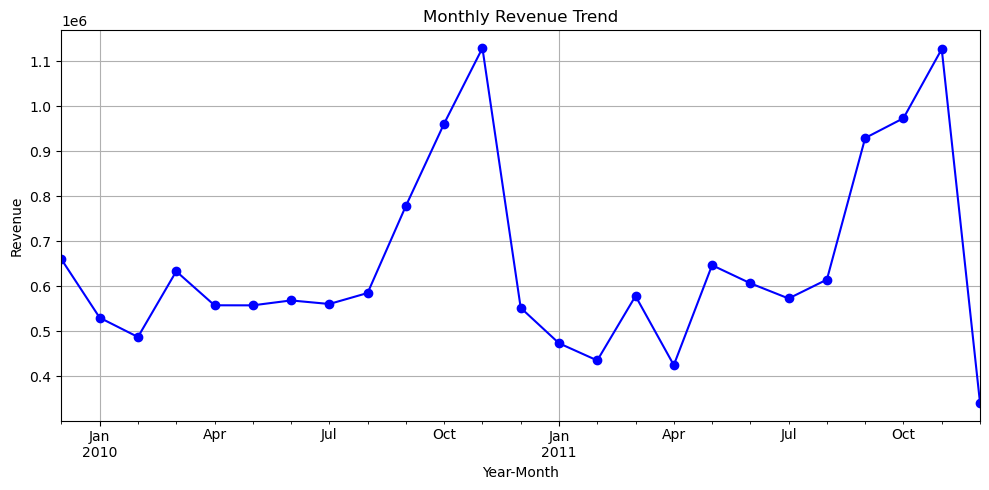

Visualization 1 generated successfully.


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)
df['Revenue'] = df['Quantity'] * df['Price']
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
# Let's test saving a couple of visualizations to make sure code works
monthly_rev = df.groupby('YearMonth')['Revenue'].sum()
plt.figure(figsize=(10, 5))
monthly_rev.plot(kind='line', marker='o', color='b')
plt.title('Monthly Revenue Trend')
plt.xlabel('Year-Month')
plt.ylabel('Revenue')
plt.grid(True)
plt.tight_layout()
plt.savefig('monthly_revenue.png')
plt.show()
plt.close()
print("Visualization 1 generated successfully.")

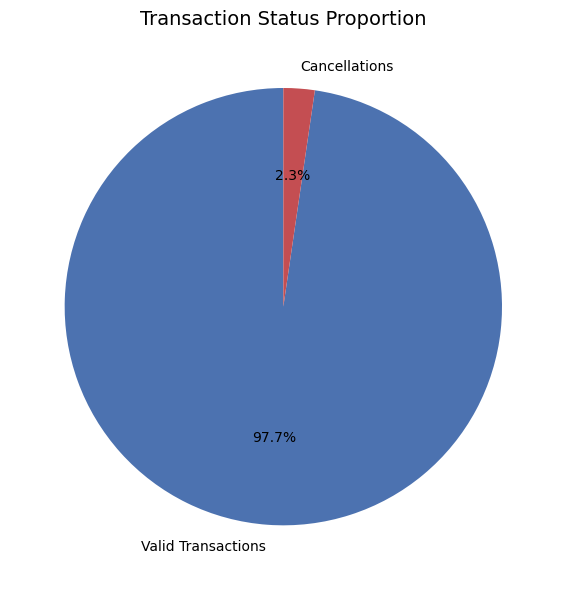

In [30]:
# Flag cancellations
df['IsCancelled'] = df['Invoice'].astype(str).str.startswith('C') | (df['Quantity'] < 0)
counts = df['IsCancelled'].value_counts()
# Plot pie chart
plt.figure(figsize=(6, 6))
counts.plot(kind='pie', labels=['Valid Transactions', 'Cancellations'], autopct='%1.1f%%', colors=['#4C72B0', '#C44E52'], startangle=90)
plt.title('Transaction Status Proportion', fontsize=14)
plt.ylabel('')
plt.tight_layout()
plt.show()

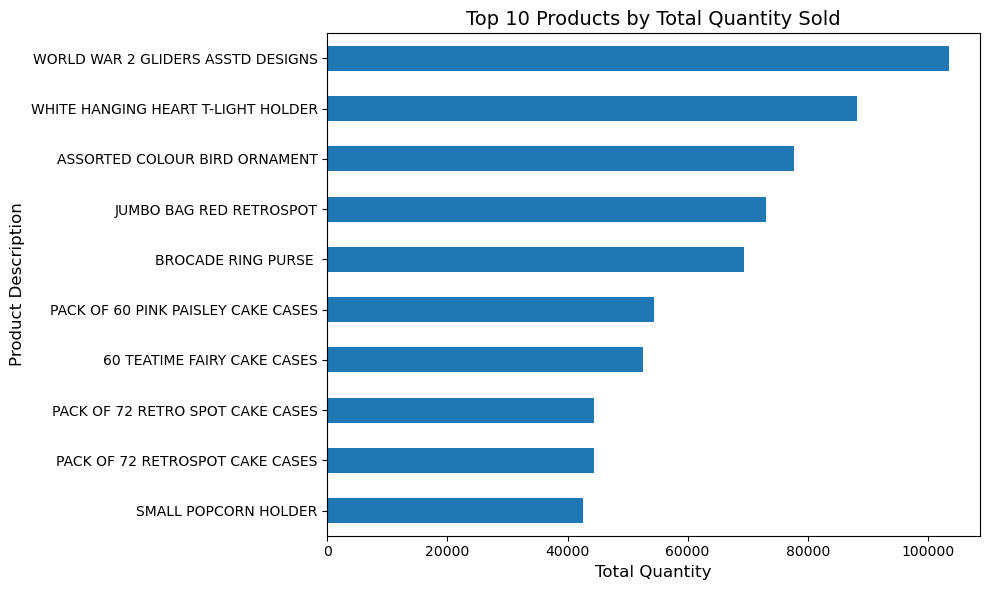

In [33]:
# Top 10 products by Quantity
top_products = df.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)
# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind='barh', color='#1f77b4')
plt.title('Top 10 Products by Total Quantity Sold', fontsize=14)
plt.xlabel('Total Quantity', fontsize=12)
plt.ylabel('Product Description', fontsize=12)
plt.tight_layout()
plt.show()

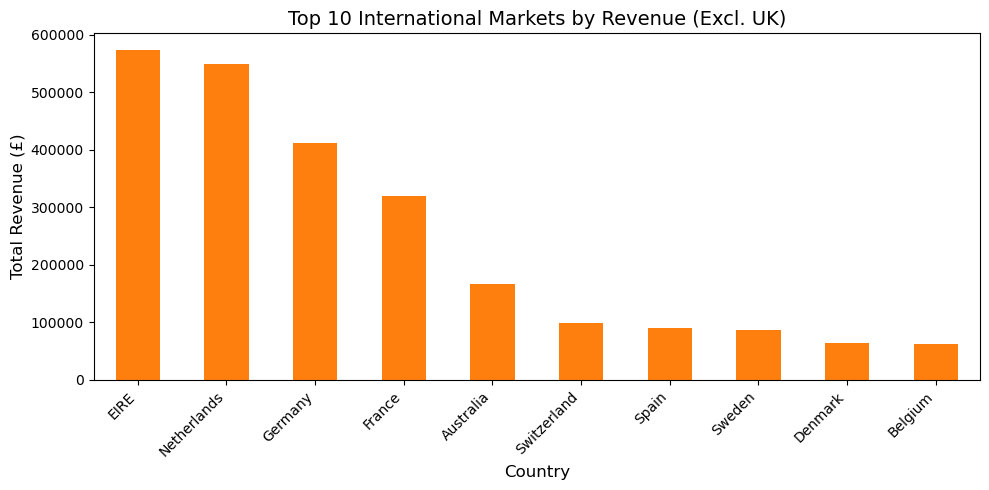

In [34]:
df['Revenue'] = df['Quantity'] * df['Price']
# Exclude United Kingdom for better international scale visualization
intl_df = df[df['Country'] != 'United Kingdom']
top_countries = intl_df.groupby('Country')['Revenue'].sum().sort_values(ascending=False).head(10)
# Plot bar chart
plt.figure(figsize=(10, 5))
top_countries.plot(kind='bar', color='#ff7f0e')
plt.title('Top 10 International Markets by Revenue (Excl. UK)', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Total Revenue (£)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

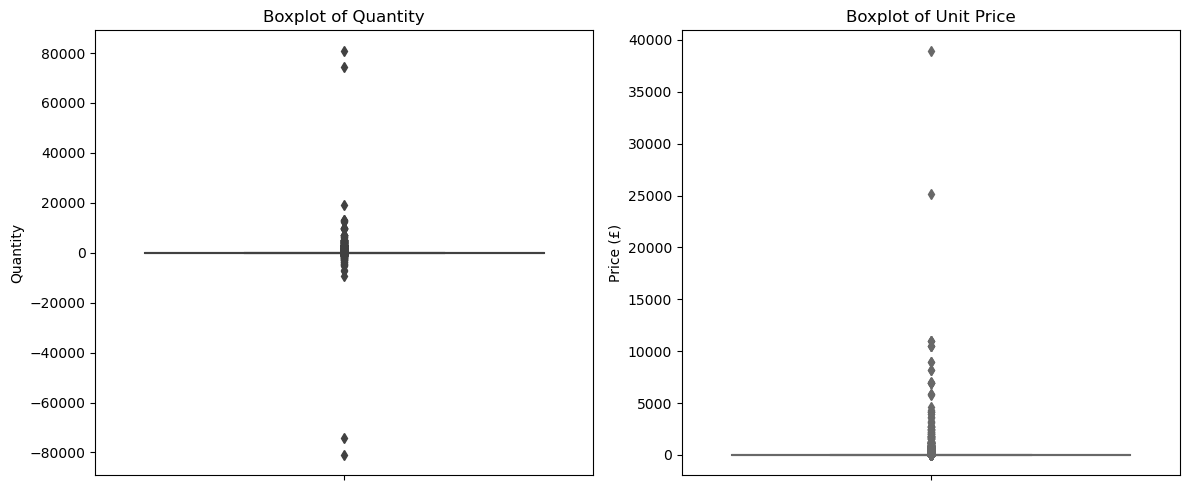

In [37]:
# Plot subplots for Quantity and Price
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df['Quantity'], ax=axes[0], color='#8c564b')
axes[0].set_title('Boxplot of Quantity', fontsize=12)
axes[0].set_ylabel('Quantity', fontsize=10)
sns.boxplot(y=df['Price'], ax=axes[1], color='#e377c2')
axes[1].set_title('Boxplot of Unit Price', fontsize=12)
axes[1].set_ylabel('Price (£)', fontsize=10)
plt.tight_layout()
plt.show()

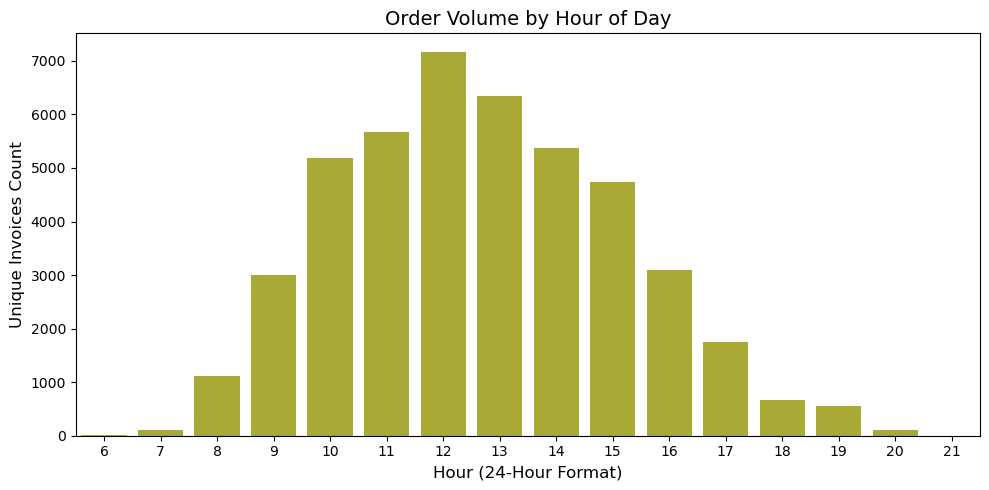

In [39]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)
# Extract hour
df['Hour'] = df['InvoiceDate'].dt.hour
hourly_counts = df.groupby('Hour')['Invoice'].nunique()
# Plot hourly activity
plt.figure(figsize=(10, 5))
sns.barplot(x=hourly_counts.index, y=hourly_counts.values, color='#bcbd22')
plt.title('Order Volume by Hour of Day', fontsize=14)
plt.xlabel('Hour (24-Hour Format)', fontsize=12)
plt.ylabel('Unique Invoices Count', fontsize=12)
plt.tight_layout()
plt.show()

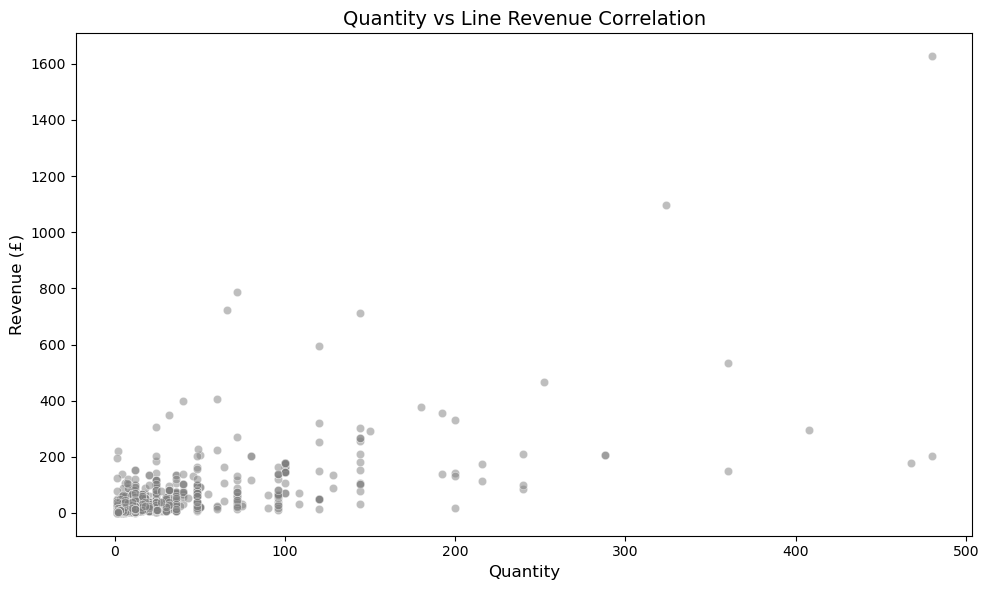

In [40]:
df['Revenue'] = df['Quantity'] * df['Price']
# Sample data to avoid overplotting in large scatter plots
sample_df = df[(df['Quantity'] > 0) & (df['Quantity'] < 500) & (df['Price'] > 0) & (df['Price'] < 200)].sample(5000, random_state=42)
# Plot scatter
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_df, x='Quantity', y='Revenue', alpha=0.5, color='#7f7f7f')
plt.title('Quantity vs Line Revenue Correlation', fontsize=14)
plt.xlabel('Quantity', fontsize=12)
plt.ylabel('Revenue (£)', fontsize=12)
plt.tight_layout()
plt.show()